# How Much Fuel Does a Car Need? ⛽🚗
### Predicting fuel consumption (L/100 km) from engine size — Mini Project 01

My first Machine Learning project. It covers the main ideas of **Chapter 1 ("The Machine Learning Landscape")** of *Hands-On Machine Learning with Scikit-Learn, Keras & TensorFlow* (3rd ed., Aurélien Géron), applied to my own question and my own data.

---

**The question:** If we only know the size of a car's engine (in litres), can we predict how much fuel it uses per 100 km?

**The data:** Official fuel consumption ratings for **all new cars of model year 2026** sold in Canada, published by Natural Resources Canada. The values are measured in standard lab tests and given in **L/100 km**, the same unit we use in Germany.

**What this notebook does:**
1. Load and explore the data
2. Split the data into a **training set** and a **test set**
3. Train two different models: **Linear Regression** and **k-Nearest Neighbors**
4. Measure how good they are on cars they have never seen
5. Learn three key lessons with real examples:
   - the training data must be **representative** (the hybrid car problem)
   - **overfitting** (a model that memorizes instead of learning)
   - **regularization** (how to keep a model simple)

> 💡 **How to use this notebook:** run the cells one by one from top to bottom with `Shift + Enter`. Read the text *before* each cell, then look at the output.

## 1. Import the libraries

A *library* is ready-made code written by other people.

| Library | Nickname | Used for |
|---|---|---|
| `pandas` | `pd` | Tables of data (like Excel in Python) |
| `numpy` | `np` | Fast math with arrays of numbers |
| `matplotlib.pyplot` | `plt` | Plots |
| `sklearn` (Scikit-Learn) | – | Machine Learning models and tools |

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error

print("All libraries imported!")

All libraries imported!


Some plot settings, and a small helper function that saves every plot as a PNG file in the folder `images/`. The README on GitHub shows these images.

In [2]:
plt.rc("font", size=12)
plt.rc("axes", labelsize=13, titlesize=14)

IMAGES_PATH = Path("images")
IMAGES_PATH.mkdir(exist_ok=True)

def save_fig(name):
    """Save the current plot to images/<name>.png"""
    plt.tight_layout()
    plt.savefig(IMAGES_PATH / f"{name}.png", dpi=150)

## 2. Load the data

The data comes from the **Government of Canada Open Data portal** (licence: *Open Government Licence – Canada*, free to use with attribution).

The code below first tries to download the **newest version** from the official website. If that does not work (for example, no internet), it uses the copy saved in the `data/` folder of this project.

> 💡 `try:` / `except:` means: *"try this; if an error happens, do that instead."* It keeps the notebook from crashing.

In [3]:
URL_2026 = ("https://open.canada.ca/data/dataset/98f1a129-f628-4ce4-b24d-6f16bf24dd64/"
            "resource/9df1b18d-d036-4783-a61c-99f1f75b3ac5/download/my2026-fuel-consumption-ratings.csv")
LOCAL_2026 = Path("data") / "my2026-fuel-consumption-ratings.csv"

try:
    cars = pd.read_csv(URL_2026)
    print("Downloaded the newest data from open.canada.ca")
except Exception:
    cars = pd.read_csv(LOCAL_2026)
    print("No download possible - using the local copy in data/")

cars.head()

No download possible - using the local copy in data/


,Model year,Make,Model,Vehicle class,Engine size (L),Cylinders,Transmission,Fuel type,City (L/100 km),Highway (L/100 km),Combined (L/100 km),Combined (mpg),CO2 emissions (g/km),CO2 rating,Smog rating
0,2026,Acura,ADX AWD,Station wagon: Small,1.5,4,AV7,Z,9.1,7.7,8.5,33,199,5,5
1,2026,Acura,Integra A-SPEC,Full-size,1.5,4,AV7,Z,8.0,6.3,7.3,39,171,6,6
2,2026,Acura,Integra A-SPEC,Full-size,1.5,4,M6,Z,8.9,6.5,7.8,36,181,6,5
3,2026,Acura,Integra Type S,Full-size,2.0,4,M6,Z,11.1,8.3,9.9,29,230,5,5
4,2026,Acura,MDX SH-AWD,Sport utility vehicle: Small,3.5,6,AS10,Z,12.6,9.4,11.2,25,263,4,4


## 3. Explore the data

**Always look at the data before training a model.** First: how big is the table, and which columns does it have?

In [4]:
print("Rows (cars):", cars.shape[0])
print("Columns:    ", cars.shape[1])
print()
print(cars.columns.tolist())

Rows (cars): 613
Columns:     15

['Model year', 'Make', 'Model', 'Vehicle class', 'Engine size (L)', 'Cylinders', 'Transmission', 'Fuel type', 'City (L/100 km)', 'Highway (L/100 km)', 'Combined (L/100 km)', 'Combined (mpg)', 'CO2 emissions (g/km)', 'CO2 rating', 'Smog rating']


For this project we only need two columns:
- **`Engine size (L)`** → the *feature* (input)
- **`Combined (L/100 km)`** → the *target* (what we want to predict). "Combined" = 55 % city driving + 45 % highway driving.

The other columns are useful for later projects (e.g. using several features at once).

Let's look at the numbers:

In [5]:
FEATURE = "Engine size (L)"
TARGET = "Combined (L/100 km)"

cars[[FEATURE, TARGET]].describe().round(2)

,Engine size (L),Combined (L/100 km)
count,613.00,613.00
mean,2.98,10.79
std,1.23,2.86
min,1.20,4.40
25%,2.00,8.70
50%,2.70,10.70
75%,3.50,12.60
max,6.70,19.70


**How to read this:** `mean` = average, `std` = how spread out the values are, `min`/`max` = smallest/largest, `50%` = median.

So a typical 2026 car has a **2.7 L** engine (median) and uses about **10.7 L/100 km**. The range is big: from 4.4 L/100 km up to almost 20.

Which cars are the most and the least efficient?

In [6]:
columns_to_show = ["Make", "Model", "Vehicle class", FEATURE, TARGET]

print("The 5 most efficient cars:")
display(cars.sort_values(TARGET).head(5)[columns_to_show])

print("The 5 cars that use the most fuel:")
display(cars.sort_values(TARGET, ascending=False).head(5)[columns_to_show])

The 5 most efficient cars:


,Make,Model,Vehicle class,Engine size (L),Combined (L/100 km)
341,Kia,Niro FE,Sport utility vehicle: Small,1.6,4.4
554,Toyota,Corolla Hybrid,Compact,1.8,4.7
283,Hyundai,Elantra Hybrid,Mid-size,1.6,4.7
340,Kia,Niro,Sport utility vehicle: Small,1.6,4.8
577,Toyota,Prius AWD,Mid-size,2.0,4.8


The 5 cars that use the most fuel:


,Make,Model,Vehicle class,Engine size (L),Combined (L/100 km)
195,Ford,F-150 Raptor R 4X4,Pickup truck: Standard,5.2,19.7
237,GMC,Sierra 4WD FFV,Pickup truck: Standard,5.3,19.2
209,Ford,Mustang GTD,Subcompact,5.2,19.2
131,Chevrolet,Silverado 4WD FFV,Pickup truck: Standard,5.3,19.2
164,Ferrari,Purosangue,Compact,6.5,19.0


👀 Notice: the most efficient cars are all **hybrids** (they have an electric motor that helps the engine). Remember this — it will be important in Lesson 1.

How many cars use which fuel? The dataset uses letter codes:
**X** = regular gasoline, **Z** = premium gasoline, **D** = diesel, **E** = E85 (ethanol).

In [7]:
cars["Fuel type"].value_counts()

Fuel type
Z    300
X    294
D     16
E      3
Name: count, dtype: int64

## 4. Visualize the data

A **scatter plot**: every dot is one car. `alpha=0.4` makes the dots a bit transparent, so we can see where many cars overlap.

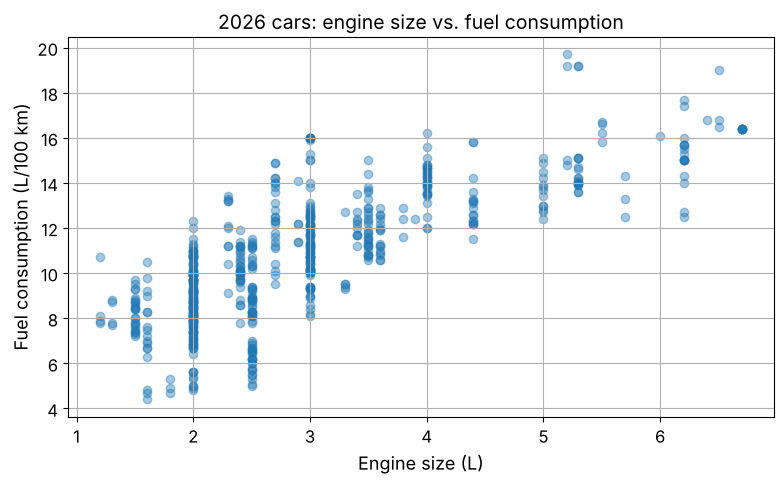

In [8]:
plt.figure(figsize=(8, 5))
plt.scatter(cars[FEATURE], cars[TARGET], alpha=0.4)
plt.xlabel("Engine size (L)")
plt.ylabel("Fuel consumption (L/100 km)")
plt.title("2026 cars: engine size vs. fuel consumption")
plt.grid(True)
save_fig("01_engine_vs_consumption")
plt.show()

There is a clear trend: **bigger engines use more fuel**. But the dots are quite spread out — cars with the same engine size can differ by several litres (weight, shape, hybrid or not, …). So no model using *only* engine size will be perfect.

> 💡 The dots form vertical "columns" because engine sizes are rounded (1.5 L, 2.0 L, 3.0 L, …).

### Bonus: has fuel consumption changed in the last 10 years?

There is a second file with all cars from 2015 to 2024. `pd.concat()` glues two tables together (one below the other). Then `groupby()` computes the average for each model year.

In [9]:
URL_2015_2024 = ("https://open.canada.ca/data/dataset/98f1a129-f628-4ce4-b24d-6f16bf24dd64/"
                 "resource/c98b9dc8-b23f-4cd8-8b19-e892da1e4688/download/my2015-2024-fuel-consumption-ratings.csv")
LOCAL_2015_2024 = Path("data") / "my2015-2024-fuel-consumption-ratings.csv"

try:
    cars_old = pd.read_csv(URL_2015_2024)
except Exception:
    cars_old = pd.read_csv(LOCAL_2015_2024)

all_years = pd.concat([cars_old, cars])
yearly = all_years.groupby("Model year")[[FEATURE, TARGET]].mean().round(2)
yearly["Number of models"] = all_years.groupby("Model year").size()
yearly

,Engine size (L),Combined (L/100 km),Number of models
Model year,,,
2015,3.18,10.98,1128
2016,3.11,10.81,1106
2017,3.11,10.87,1058
2018,3.11,10.85,1083
2019,3.11,10.87,1056
2020,3.16,10.97,975
2021,3.22,11.10,970
2022,3.20,11.15,976
2023,3.16,11.19,919


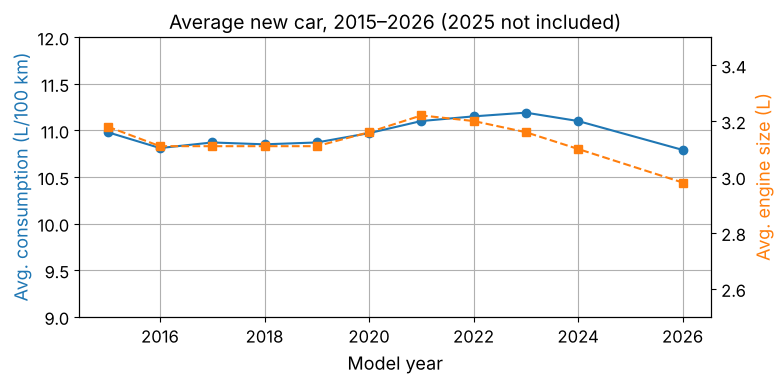

In [10]:
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(yearly.index, yearly[TARGET], "o-", color="tab:blue")
ax1.set_xlabel("Model year")
ax1.set_ylabel("Avg. consumption (L/100 km)", color="tab:blue")
ax1.set_ylim(9, 12)

ax2 = ax1.twinx()   # a second y-axis on the right side
ax2.plot(yearly.index, yearly[FEATURE], "s--", color="tab:orange")
ax2.set_ylabel("Avg. engine size (L)", color="tab:orange")
ax2.set_ylim(2.5, 3.5)

plt.title("Average new car, 2015–2026 (2025 not included)")
ax1.grid(True)
save_fig("02_trend_2015_2026")
plt.show()

**Interesting finding:** the average consumption of new car models stayed almost the same (about 11 L/100 km) from 2015 to 2024. 2026 looks a bit lower, with smaller engines on average.

⚠️ Be careful with that last point: the 2026 file has fewer models (613 vs. about 1,000 in earlier years), because new models are added during the year. A trend based on incomplete data can be misleading — always check *how many* data points stand behind an average.

From now on we use only the **2026 data**.

## 5. Split the data: training set and test set

This is one of the most important ideas in Machine Learning.

If we test a model on the same cars it learned from, it is like a student who sees the exam questions before the exam — the result looks great but says nothing. So we **hide 20 % of the cars** (the *test set*) and use them only at the end to check the model on cars it has **never seen**.

- `test_size=0.2` → 20 % test, 80 % training
- `random_state=42` → the random split is the same every time we run the notebook (any number works; 42 is a popular choice)

In [11]:
train_set, test_set = train_test_split(cars, test_size=0.2, random_state=42)

print("Training cars:", len(train_set))
print("Test cars:    ", len(test_set))

Training cars: 490
Test cars:     123


Scikit-Learn needs:
- **`X`** → the features, as a **2D table** (rows × columns). That's why we use **double brackets** `[[FEATURE]]`, even for one column.
- **`y`** → the target, as a simple column (single brackets).

In [12]:
X_train = train_set[[FEATURE]]
y_train = train_set[TARGET]

X_test = test_set[[FEATURE]]
y_test = test_set[TARGET]

print("X_train shape:", X_train.shape, "→ 2D: (rows, columns)")
print("y_train shape:", y_train.shape, "→ 1D: just a list of numbers")

X_train shape: (490, 1) → 2D: (rows, columns)
y_train shape: (490,) → 1D: just a list of numbers


## 6. Model 1 — Linear Regression (model-based learning)

The model assumes a **straight line**:

$$\text{consumption} = \theta_0 + \theta_1 \times \text{engine size}$$

- $\theta_0$ → the **intercept** (where the line starts at engine size 0)
- $\theta_1$ → the **slope** (extra L/100 km for every extra litre of engine)

*Training* = finding the best values for $\theta_0$ and $\theta_1$. After that, the model only needs these two numbers — it can forget the data. This is called **model-based learning**.

Every Scikit-Learn model works with the same 3 steps:
1. **create** → `model = LinearRegression()`
2. **train** → `model.fit(X_train, y_train)`
3. **predict** → `model.predict(X_new)`

In [13]:
lin_reg = LinearRegression()        # 1. create
lin_reg.fit(X_train, y_train)       # 2. train

theta0 = lin_reg.intercept_
theta1 = lin_reg.coef_[0]
print(f"θ0 (intercept) = {theta0:.2f} L/100 km")
print(f"θ1 (slope)     = {theta1:.2f} L/100 km per litre of engine size")
print()
print(f"Meaning: every extra litre of engine size adds about {theta1:.1f} L/100 km.")

θ0 (intercept) = 5.48 L/100 km
θ1 (slope)     = 1.78 L/100 km per litre of engine size

Meaning: every extra litre of engine size adds about 1.8 L/100 km.


### Predict for a car the model has never seen

The **Volkswagen Golf R** (2.0 L engine) is in our *test set*, so the model did not see it during training. What does the model predict?

> 💡 `X_new` must be a 2D table with the same column name as during training. `.item()` takes the single number out of the result array.

In [14]:
golf_r = test_set[test_set["Model"] == "Golf R"]
X_new = golf_r[[FEATURE]]

prediction = lin_reg.predict(X_new).item()   # 3. predict
actual = golf_r[TARGET].item()

print(f"VW Golf R, engine size: {X_new[FEATURE].item()} L")
print(f"Predicted consumption:  {prediction:.1f} L/100 km")
print(f"Real consumption:       {actual:.1f} L/100 km")
print(f"Error:                  {abs(prediction - actual):.1f} L/100 km")

VW Golf R, engine size: 2.0 L
Predicted consumption:  9.0 L/100 km
Real consumption:       9.3 L/100 km
Error:                  0.3 L/100 km


Let's draw the learned line together with the training data.

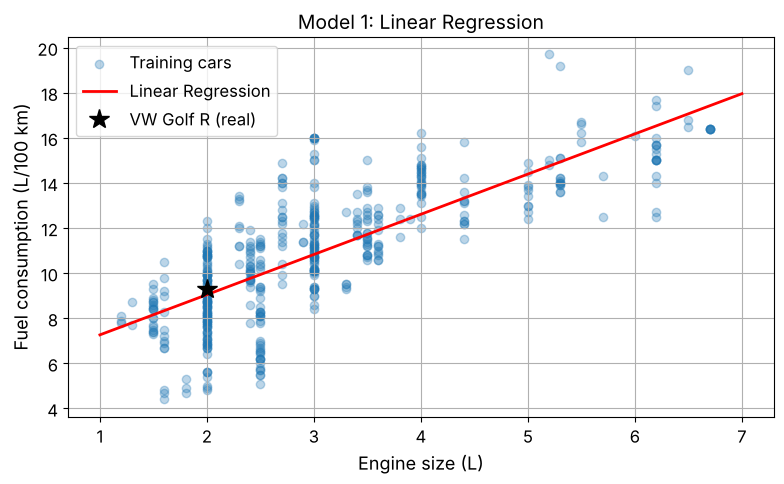

In [15]:
x_line = pd.DataFrame({FEATURE: np.linspace(1, 7, 100)})   # 100 engine sizes from 1 to 7 litres

plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, alpha=0.3, label="Training cars")
plt.plot(x_line, lin_reg.predict(x_line), "r-", linewidth=2, label="Linear Regression")
plt.plot(X_new, actual, "k*", markersize=15, label="VW Golf R (real)")
plt.xlabel("Engine size (L)")
plt.ylabel("Fuel consumption (L/100 km)")
plt.title("Model 1: Linear Regression")
plt.grid(True)
plt.legend()
save_fig("03_linear_regression")
plt.show()

### How good is the model? → Mean Absolute Error (MAE)

One car is not enough to judge a model. We check **all test cars**:

**MAE** = the average of |prediction − real value|. It is in the same unit as the target, so it is easy to understand: *"on average, the model is wrong by … L/100 km."*

In [16]:
lin_test_predictions = lin_reg.predict(X_test)
lin_mae = mean_absolute_error(y_test, lin_test_predictions)

print(f"Linear Regression - MAE on the test set: {lin_mae:.2f} L/100 km")

Linear Regression - MAE on the test set: 1.30 L/100 km


## 7. Model 2 — k-Nearest Neighbors (instance-based learning)

This model works completely differently. It does **not** learn a line. It **remembers all training cars**, and to predict a new car it:
1. finds the **k training cars with the most similar engine size**
2. returns the **average** consumption of these k cars

This is called **instance-based learning**. We use **k = 5**.

Look: the code is the same 3 steps — only the first line changes!

In [17]:
knn_reg = KNeighborsRegressor(n_neighbors=5)   # 1. create
knn_reg.fit(X_train, y_train)                  # 2. train (= just store the data)

knn_prediction = knn_reg.predict(X_new).item() # 3. predict
print(f"k-NN prediction for the VW Golf R: {knn_prediction:.1f} L/100 km (real: {actual:.1f})")

k-NN prediction for the VW Golf R: 8.9 L/100 km (real: 9.3)


Which 5 cars did k-NN use? `kneighbors()` returns the *positions* of the nearest training cars; `.iloc[...]` picks those rows from the table.

In [18]:
distances, positions = knn_reg.kneighbors(X_new)

neighbours = train_set.iloc[positions[0]][["Make", "Model", FEATURE, TARGET]]
neighbours

,Make,Model,Engine size (L),Combined (L/100 km)
367,Land Rover,Range Rover Velar P250,2.0,10.0
606,Volkswagen,Tiguan,2.0,8.5
344,Kia,Seltos AWD,2.0,8.2
412,Mercedes-Benz,AMG C 43 4MATIC Sedan,2.0,10.8
281,Hyundai,Elantra,2.0,6.9


In [19]:
print("Average of these 5 cars:", round(neighbours[TARGET].mean(), 2))

Average of these 5 cars: 8.88


✅ The prediction is exactly the average of the 5 neighbours.

⚠️ Did you notice? Many cars have a 2.0 L engine, so all 5 neighbours have *exactly* the same engine size as the Golf R — and there are many more 2.0 L cars than 5. Which 5 are chosen depends on the order of the data. That's a weakness of k-NN with only one rounded feature.

Now the MAE on the whole test set:

In [20]:
knn_mae = mean_absolute_error(y_test, knn_reg.predict(X_test))
print(f"k-NN (k=5) - MAE on the test set: {knn_mae:.2f} L/100 km")

k-NN (k=5) - MAE on the test set: 1.18 L/100 km


### Compare the two models

In [21]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "k-Nearest Neighbors (k=5)"],
    "Test MAE (L/100 km)": [lin_mae, knn_mae],
}).round(2)
results

,Model,Test MAE (L/100 km)
0,Linear Regression,1.30
1,k-Nearest Neighbors (k=5),1.18


In [22]:
# Predictions for the first 8 cars of the test set, side by side
comparison = test_set[["Make", "Model", FEATURE, TARGET]].head(8).copy()
comparison["Linear Regression"] = lin_reg.predict(comparison[[FEATURE]]).round(1)
comparison["k-NN"] = knn_reg.predict(comparison[[FEATURE]]).round(1)
comparison

,Make,Model,Engine size (L),Combined (L/100 km),Linear Regression,k-NN
370,Lexus,ES 350h AWD,2.5,5.3,9.9,8.5
101,Cadillac,CT5-V AWD,3.0,11.7,10.8,10.5
131,Chevrolet,Silverado 4WD FFV,5.3,19.2,14.9,15.1
393,Mazda,CX-30 4WD,2.5,8.7,9.9,8.5
609,Volvo,V90 CC B6 AWD,2.0,9.3,9.0,8.9
163,Ferrari,F80,2.9,14.1,10.7,11.1
231,GMC,Sierra 4WD,2.7,13.6,10.3,12.9
181,Ford,Escape Hybrid AWD,2.5,6.0,9.9,8.5


Both models are wrong by about **1.2–1.3 L/100 km** on average. That is not bad for using only *one* feature. In the table you can see where they fail: the **Lexus ES 350h** is a hybrid and uses much less than its engine size suggests. That leads us to the first lesson.

---
# Part 2 — Three lessons from Chapter 1, with real cars

## 8. Lesson 1 — The training data must be representative

**Experiment:** imagine we collected our training data a few years ago, when there were almost no hybrid cars. We train a model **only on non-hybrid cars**, and then ask it about hybrids.

`str.contains("Hybrid")` checks if the word "Hybrid" is in the model name. The `~` sign means **NOT**.

In [23]:
is_hybrid = cars["Model"].str.contains("Hybrid")

hybrids = cars[is_hybrid]
non_hybrids = cars[~is_hybrid]

print("Hybrid models:    ", len(hybrids))
print("Non-hybrid models:", len(non_hybrids))

Hybrid models:     37
Non-hybrid models: 576


In [24]:
model_no_hybrids = LinearRegression()
model_no_hybrids.fit(non_hybrids[[FEATURE]], non_hybrids[TARGET])

mae_non_hybrids = mean_absolute_error(non_hybrids[TARGET], model_no_hybrids.predict(non_hybrids[[FEATURE]]))
mae_hybrids = mean_absolute_error(hybrids[TARGET], model_no_hybrids.predict(hybrids[[FEATURE]]))

print(f"Error on normal cars (it knows this kind): {mae_non_hybrids:.2f} L/100 km")
print(f"Error on hybrids     (never seen):         {mae_hybrids:.2f} L/100 km")

Error on normal cars (it knows this kind): 1.30 L/100 km
Error on hybrids     (never seen):         2.57 L/100 km


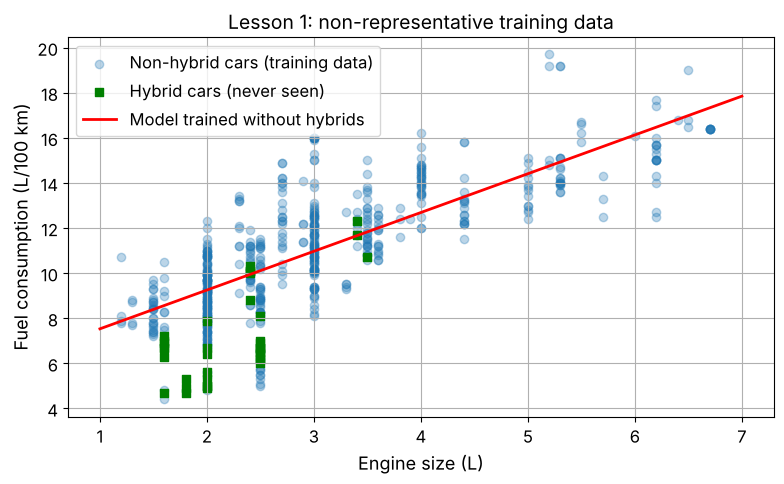

In [25]:
plt.figure(figsize=(8, 5))
plt.scatter(non_hybrids[FEATURE], non_hybrids[TARGET], alpha=0.3, label="Non-hybrid cars (training data)")
plt.scatter(hybrids[FEATURE], hybrids[TARGET], color="green", marker="s", label="Hybrid cars (never seen)")
plt.plot(x_line, model_no_hybrids.predict(x_line), "r-", linewidth=2, label="Model trained without hybrids")
plt.xlabel("Engine size (L)")
plt.ylabel("Fuel consumption (L/100 km)")
plt.title("Lesson 1: non-representative training data")
plt.grid(True)
plt.legend()
save_fig("04_representative_data")
plt.show()

**What we learn:** most green squares are far **below** the red line (the few above it are sporty hybrids that use the electric motor for extra power, not for saving fuel). The model thinks hybrids use about **2.5 L/100 km more** than they really do — twice its normal error. It is not a bad model; it simply never saw this kind of car.

👉 A model can only be as good as its training data. If important cases are missing (new technology, new customer groups, a new region, …), the predictions for those cases will be wrong. In real projects this happens all the time when the world changes after a model is trained.

## 9. Lesson 2 — Overfitting

**Experiment:** we give a model only **15 training cars** and make it very **flexible**: instead of a straight line, a **polynomial of degree 10** (a very wiggly curve).

A **pipeline** connects several steps into one model:
1. `PolynomialFeatures(degree=10)` → creates new features: size, size², size³, … size¹⁰
2. `StandardScaler()` → puts all these numbers on a similar scale (size¹⁰ would otherwise be huge)
3. `LinearRegression()` → fits the curve

In [26]:
small_train = train_set.sample(15, random_state=42)   # pick 15 random training cars
X_small = small_train[[FEATURE]]
y_small = small_train[TARGET]

poly_model = make_pipeline(
    PolynomialFeatures(degree=10, include_bias=False),
    StandardScaler(),
    LinearRegression(),
)
poly_model.fit(X_small, y_small)

poly_train_mae = mean_absolute_error(y_small, poly_model.predict(X_small))
poly_test_mae = mean_absolute_error(y_test, poly_model.predict(X_test))

print(f"Error on its 15 training cars: {poly_train_mae:.2f} L/100 km  ← looks great!")
print(f"Error on the test cars:        {poly_test_mae:.2f} L/100 km  ← terrible!")

Error on its 15 training cars: 0.60 L/100 km  ← looks great!
Error on the test cars:        9.22 L/100 km  ← terrible!


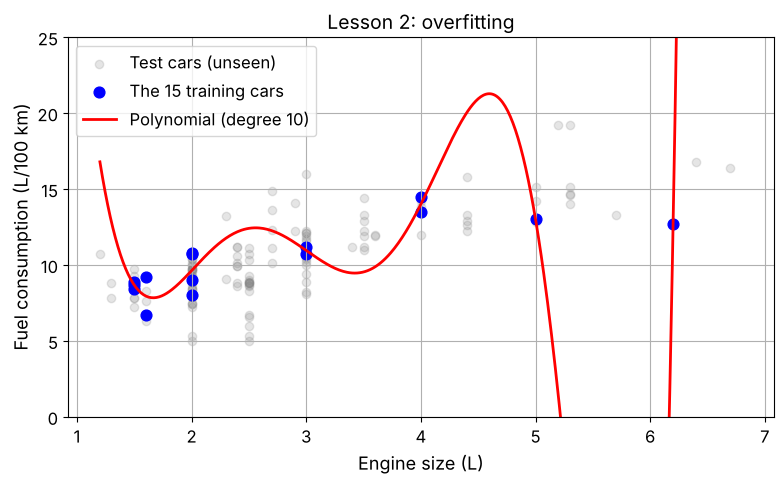

In [27]:
x_fine = pd.DataFrame({FEATURE: np.linspace(1.2, 6.8, 500)})

plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, alpha=0.2, color="gray", label="Test cars (unseen)")
plt.scatter(X_small, y_small, color="blue", s=60, label="The 15 training cars")
plt.plot(x_fine, poly_model.predict(x_fine), "r-", linewidth=2, label="Polynomial (degree 10)")
plt.ylim(0, 25)
plt.xlabel("Engine size (L)")
plt.ylabel("Fuel consumption (L/100 km)")
plt.title("Lesson 2: overfitting")
plt.grid(True)
plt.legend(loc="upper left")
save_fig("05_overfitting")
plt.show()

**What we learn:** the red curve bends to pass close to the 15 blue cars, but between and outside them it makes wild jumps that make no sense for real cars.

👉 This is **overfitting**: the model learned the *random noise* of its few training examples instead of the real pattern. It is very good on the training data but bad on new data — like a student who memorizes old exam answers without understanding the subject.

**Typical causes:** a model that is too complex for the amount of data, and too little training data.

## 10. Lesson 3 — Regularization

**Regularization** = putting a *constraint* on the model so it cannot become too wild.

`Ridge` is a Linear Regression with regularization: it is punished for using large parameter values. The parameter `alpha` sets how strong the punishment is (bigger alpha → simpler, smoother model).

We use **exactly the same** 15 cars and degree-10 features — only `LinearRegression()` is replaced by `Ridge(alpha=1)`.

In [28]:
ridge_model = make_pipeline(
    PolynomialFeatures(degree=10, include_bias=False),
    StandardScaler(),
    Ridge(alpha=1),
)
ridge_model.fit(X_small, y_small)

ridge_train_mae = mean_absolute_error(y_small, ridge_model.predict(X_small))
ridge_test_mae = mean_absolute_error(y_test, ridge_model.predict(X_test))

print(f"Error on its 15 training cars: {ridge_train_mae:.2f} L/100 km")
print(f"Error on the test cars:        {ridge_test_mae:.2f} L/100 km")

Error on its 15 training cars: 0.77 L/100 km
Error on the test cars:        1.42 L/100 km


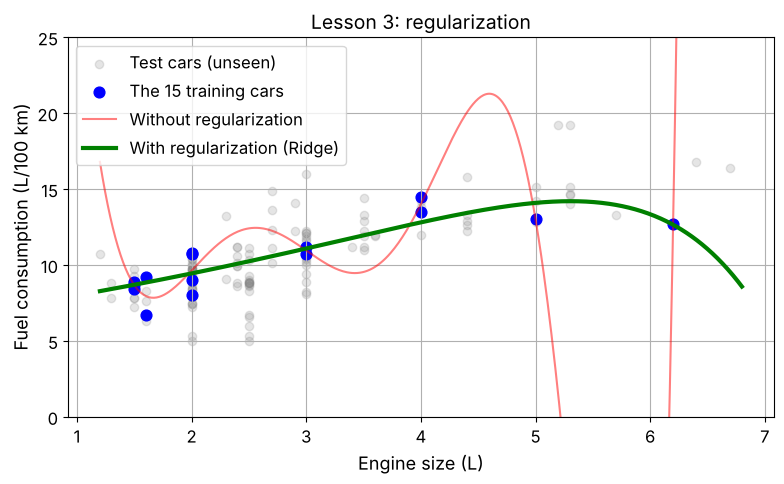

In [29]:
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, alpha=0.2, color="gray", label="Test cars (unseen)")
plt.scatter(X_small, y_small, color="blue", s=60, label="The 15 training cars")
plt.plot(x_fine, poly_model.predict(x_fine), "r-", alpha=0.5, label="Without regularization")
plt.plot(x_fine, ridge_model.predict(x_fine), "g-", linewidth=3, label="With regularization (Ridge)")
plt.ylim(0, 25)
plt.xlabel("Engine size (L)")
plt.ylabel("Fuel consumption (L/100 km)")
plt.title("Lesson 3: regularization")
plt.grid(True)
plt.legend(loc="upper left")
save_fig("06_regularization")
plt.show()

In [30]:
lesson_results = pd.DataFrame({
    "Model (15 training cars, degree 10)": ["Without regularization", "With Ridge (alpha=1)"],
    "Training MAE": [poly_train_mae, ridge_train_mae],
    "Test MAE": [poly_test_mae, ridge_test_mae],
}).round(2)
lesson_results

,"Model (15 training cars, degree 10)",Training MAE,Test MAE
0,Without regularization,0.60,9.22
1,With Ridge (alpha=1),0.77,1.42


**What we learn:** with Ridge, the error on the training cars is a bit **higher**, but the error on new cars is much **lower**. The green curve is smooth and follows the general trend.

👉 We don't want a model that is perfect on the training data. We want a model that **generalizes** — that works well on data it has never seen.

## 11. Summary — what I learned

| Concept | In one sentence |
|---|---|
| **Supervised learning / regression** | Learning from examples with known answers to predict a number. |
| **Training set vs. test set** | Keep some data hidden to honestly check the model on unseen cases. |
| **MAE** | The average size of the prediction errors, in the unit of the target. |
| **Model-based learning** | The model learns parameters (θ0, θ1) – e.g. Linear Regression. |
| **Instance-based learning** | The model stores the examples and compares new cases to them – e.g. k-NN. |
| **Scikit-Learn workflow** | create → `fit()` → `predict()`, the same for every model. |
| **Representative data** | Cases missing from the training data (hybrids) get bad predictions. |
| **Overfitting** | A too-flexible model learns noise: good on training data, bad on new data. |
| **Regularization** | Constraining the model (`Ridge`) makes it simpler and better on new data. |

### Results

| Model | Test MAE (L/100 km) |
|---|---|
| Linear Regression (all training cars) | ≈ 1.3 |
| k-NN, k = 5 (all training cars) | ≈ 1.2 |
| Polynomial degree 10 (15 cars) | ≈ 9 |
| Polynomial degree 10 + Ridge (15 cars) | ≈ 1.4 |

### Ideas to try yourself
- Change `n_neighbors=5` to `1` or `20`. What happens to the test MAE? (Hint: `k=1` is a form of overfitting.)
- Change the polynomial `degree=10` to `2` or `3`. Does it still overfit?
- Try `alpha=0.01` and `alpha=100` in `Ridge`.
- Change `random_state=42` in `sample(15, ...)` to another number. Are the results always the same?
- Use `Cylinders` as the feature instead of engine size. Is it better or worse?

---
*Next mini project → Chapter 2: an end-to-end Machine Learning project.*